# Q8. In which brain area are spikes most strongly phase-locked to its own LFP in the 4–10 Hz range?

**Idea.** The LFP of every area has a 4–10 Hz (theta) rhythm (Q2, Q5). A unit is *phase-locked* if it fires preferentially at one point of the theta cycle, for example near the trough.
For each spike, the phase of the area's own theta at that moment is read off, and the question is how concentrated those phases are.

**LFP of each area.** The channel each unit sits on is unknown, so every unit of an area is compared with the same channel: the one with the **strongest 4–10 Hz power**, where the phase estimate is most reliable.
It is band-passed at 4–10 Hz (3rd-order Butterworth, zero phase), and the Hilbert transform gives the phase.

**Measure: pairwise phase consistency (PPC; Vinck et al., 2010).** It is the average cosine of the phase difference between all pairs of a unit's spikes. It is 0 without locking and grows with locking.
The usual vector strength (PLV) is **inflated for units with few spikes**: random phases give PLV ≈ 0.3 with 20 spikes, but ≈ 0.02 with 2000. Since firing rates differ between areas (Q1), PPC, which has no such bias, is the right measure.

**Robustness checks:**
- a **bipolar** signal (that channel minus its neighbour), so theta carried by the shared reference can't create locking;
- the middle channel of the area, with no selection on theta power;
- only spikes during **strong theta**;
- PLV on exactly 500 spikes per unit;
- the fraction of units with a significant Rayleigh test.

The code lives in `c2p/q08_phase_locking.py`.

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from c2p import AREAS, AREA_COLORS, FS_LFP, RESULTS_DIR, Recording
from c2p import q08_phase_locking as q8
from c2p.stats import area_bootstrap, lmm_pairwise, per_mouse_tests

units = q8.compute()                        # cached; q8.compute(force=True) recomputes (~2 min)
units["locked"] = (units.rayleigh_p < 0.05).astype(float)
print(f"{len(units)} units from {units.mouse.nunique()} mice; spikes per unit: median {units.n_spikes.median():.0f}, min {units.n_spikes.min()}")

1449 units from 18 mice; spikes per unit: median 23111, min 303


## 1. What phase locking looks like

These are the spike-phase histograms of the most typical unit of each area in one mouse (the unit with the median PPC of its area), drawn over two theta cycles.
Phase 0° is the peak of the theta wave on the reference channel, and ±180° is the trough. The counts are divided by their mean, so a flat histogram at 1 means no locking, and a wave means locking.

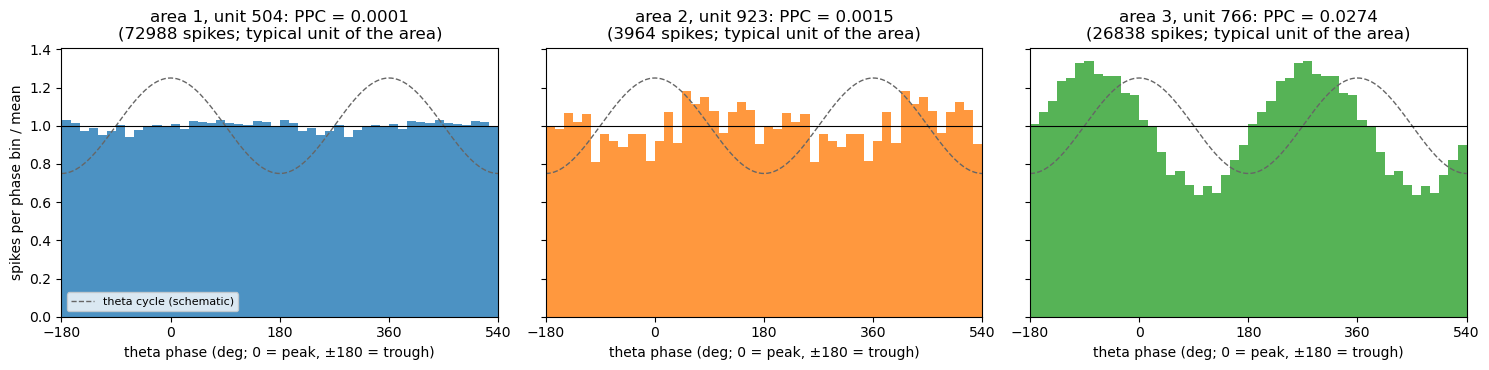

In [2]:
MOUSE = 9
rec = Recording.load(MOUSE)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, a in zip(axs, AREAS):
    u = units[(units.mouse == MOUSE) & (units.area == a)]
    r = u.iloc[(u.ppc - u.ppc.median()).abs().argsort().iloc[0]]
    ph = np.angle(q8.analytic(rec.lfp[a][int(r.lfp_channel)]))
    idx = np.round(rec.spike_times(r.cluster_id) * FS_LFP).astype(int)
    idx = idx[(idx >= 0) & (idx < len(ph))]
    h, e = np.histogram(np.degrees(ph[idx]), bins=24, range=(-180, 180))
    h = h / h.mean()                                            # 1 = what a flat (unlocked) histogram gives
    centres = e[:-1] + 7.5
    ax.bar(np.r_[centres, centres + 360], np.r_[h, h], width=15, color=AREA_COLORS[a], alpha=0.8)
    xx = np.linspace(-180, 540, 300)
    ax.plot(xx, 1 + 0.25 * np.cos(np.radians(xx)), color="0.4", lw=1, ls="--", label="theta cycle (schematic)")
    ax.axhline(1, color="k", lw=0.8)
    ax.set(xlim=(-180, 540), xticks=[-180, 0, 180, 360, 540], xlabel="theta phase (deg; 0 = peak, ±180 = trough)",
           title=f"area {a}, unit {r.cluster_id:.0f}: PPC = {r.ppc:.4f}\n({r.n_spikes:.0f} spikes; typical unit of the area)")
axs[0].set_ylabel("spikes per phase bin / mean")
axs[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()

## 2. All units

These are the PPC values of all units per area. The axis is symmetric-log, because area 3's values are 10–100× larger and PPC can be slightly negative by chance.
The right panel shows the preferred phase of the significantly locked units.

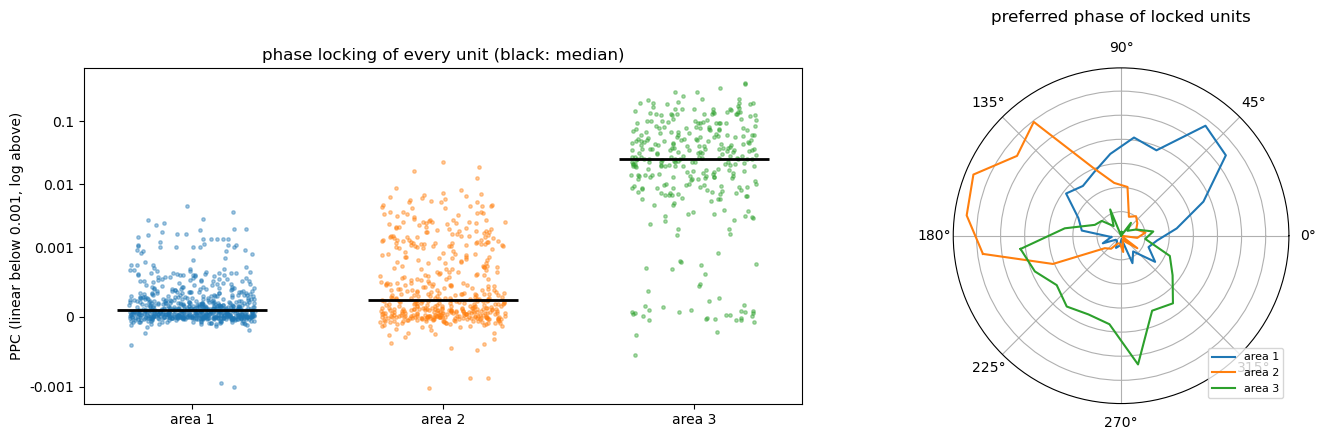

In [3]:
fig = plt.figure(figsize=(15, 4.5))
ax = fig.add_subplot(1, 2, 1)
rng = np.random.default_rng(0)
for a in AREAS:
    v = units.ppc[units.area == a]
    ax.scatter(a + rng.uniform(-0.25, 0.25, len(v)), v, s=6, alpha=0.4, color=AREA_COLORS[a])
    ax.hlines(v.median(), a - 0.3, a + 0.3, color="k", lw=2)
ax.set_yscale("symlog", linthresh=1e-3)
ax.set(xticks=AREAS, xticklabels=[f"area {a}" for a in AREAS], ylabel="PPC (linear below 0.001, log above)",
       title="phase locking of every unit (black: median)", yticks=[-1e-3, 0, 1e-3, 1e-2, 1e-1],
       yticklabels=["-0.001", "0", "0.001", "0.01", "0.1"])
ax2 = fig.add_subplot(1, 2, 2, projection="polar")
for a in AREAS:
    ph = units.preferred_phase[(units.area == a) & (units.locked == 1)]
    h, e = np.histogram(ph, bins=24, range=(-np.pi, np.pi))
    ax2.plot(np.r_[e[:-1], e[0]] + np.pi / 24, np.r_[h, h[0]] / max(h.sum(), 1), color=AREA_COLORS[a], label=f"area {a}")
ax2.set_yticklabels([]); ax2.set_title("preferred phase of locked units", pad=14); ax2.legend(loc="lower right", fontsize=8)
fig.tight_layout()

## 3. Mouse by mouse

Each line is one mouse's mean PPC per area, on a log axis.

Friedman p = 1.9e-07


,mice where x > y,n mice,wilcoxon p,wilcoxon p (Bonferroni)
pair,,,,
area 1 vs area 2,3,18,1.6e-03,0.004738
area 1 vs area 3,0,18,7.6e-06,0.000023
area 2 vs area 3,0,18,7.6e-06,0.000023


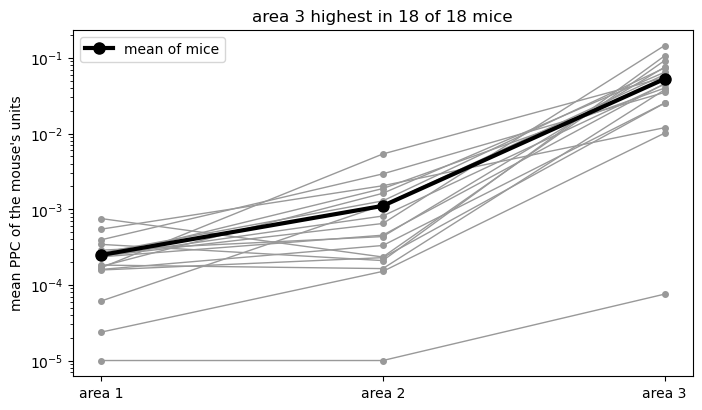

In [4]:
per_mouse, friedman, wilc = per_mouse_tests(units, "ppc")
fig, ax = plt.subplots(figsize=(8, 4.5))
for m, row in per_mouse.iterrows():
    ax.plot(AREAS, row.clip(lower=1e-5).values, "-o", color="0.6", ms=4, lw=1)
ax.plot(AREAS, per_mouse.mean().values, "-o", color="k", lw=3, ms=8, label="mean of mice")
ax.set(yscale="log", xticks=AREAS, xticklabels=[f"area {a}" for a in AREAS], ylabel="mean PPC of the mouse's units",
       title=f"area 3 highest in {(per_mouse.idxmax(axis=1) == 3).sum()} of {len(per_mouse)} mice")
ax.legend()
print("Friedman p =", f"{friedman.pvalue:.1e}")
wilc.style.format({"wilcoxon p": "{:.1e}"})

## 4. Mean and 95% CI (hierarchical bootstrap: mice, then units) and mixed model

In [5]:
t_main, boot = area_bootstrap(units, "ppc")
display(t_main.round(4))
lmm = lmm_pairwise(units, "ppc")
lmm.round(4)

,estimate,ci_low,ci_high,p (diff = 0)
area 1,0.0002,0.0002,0.0003,NaN
area 2,0.0009,0.0005,0.0013,NaN
area 3,0.0494,0.0364,0.0637,NaN
area 1 − area 2,-0.0007,-0.0011,-0.0003,0.0
area 1 − area 3,-0.0491,-0.0635,-0.0362,0.0
area 2 − area 3,-0.0485,-0.0629,-0.0355,0.0


,coef,ci_low,ci_high,p,converged,p (Bonferroni)
contrast,,,,,,
area 1 − area 2,-0.0007,-0.0038,0.0025,0.6771,False,1.0
area 1 − area 3,-0.0523,-0.0717,-0.0329,0.0000,True,0.0
area 2 − area 3,-0.0516,-0.0710,-0.0322,0.0000,True,0.0


## 5. Robustness

Each row repeats the comparison with one change. "Locked" is the fraction of units with Rayleigh p < 0.05.
With thousands of spikes per unit the Rayleigh test flags even tiny locking as significant, so that row mostly shows that **locking strength**, not its mere presence, separates the areas.

In [6]:
rows = {}
for col, lab in [("ppc", "main: PPC, strongest-theta channel"), ("ppc_bipolar", "PPC, bipolar (local) signal"),
                 ("ppc_middle", "PPC, middle channel"), ("ppc_high_theta", "PPC, strong-theta periods only"),
                 ("plv_500", "PLV on 500 spikes per unit"), ("locked", "fraction significantly locked")]:
    d = units.dropna(subset=[col])
    pm, fr, w = per_mouse_tests(d, col)
    rows[lab] = {**{f"area {a}": d[d.area == a][col].mean() for a in AREAS},
                 "highest (pooled)": f"area {d.groupby('area')[col].mean().idxmax()}",
                 "area 3 highest in n mice": int((pm.idxmax(axis=1) == 3).sum()),
                 "Wilcoxon p 3 vs 2": w.loc["area 2 vs area 3", "wilcoxon p"],
                 "Wilcoxon p 3 vs 1": w.loc["area 1 vs area 3", "wilcoxon p"]}
robust = pd.DataFrame(rows).T
robust

,area 1,area 2,area 3,highest (pooled),area 3 highest in n mice,Wilcoxon p 3 vs 2,Wilcoxon p 3 vs 1
"main: PPC, strongest-theta channel",0.000218,0.000888,0.049368,area 3,18,0.000008,0.000008
"PPC, bipolar (local) signal",0.000332,0.002165,0.040144,area 3,17,0.000053,0.000008
"PPC, middle channel",0.000568,0.003082,0.026684,area 3,16,0.000053,0.000015
"PPC, strong-theta periods only",0.000358,0.001523,0.075544,area 3,17,0.000015,0.000015
PLV on 500 spikes per unit,0.042562,0.048872,0.188574,area 3,17,0.000015,0.000008
fraction significantly locked,0.562404,0.615063,0.92236,area 3,15,0.001002,0.000015


## 6. Answer for the questionnaire

In [7]:
from c2p.questionnaire import fill_pdf, record_answer, record_meta

answer = t_main.iloc[:3, :3].copy()
answer.columns = ["Mean", "CI low", "CI high"]
fmt = lambda x: f"{x:.4f}"
rows = [(fmt(r.Mean), f"[{fmt(r['CI low'])}, {fmt(r['CI high'])}]", "PPC (unitless)") for _, r in answer.iterrows()]
answer.to_csv(RESULTS_DIR / "q08_answer.csv")
m = t_main.estimate
lk = units.groupby("area").locked.mean()
expl = (
    f"For each area I took the LFP channel with the strongest 4–10 Hz power, band-passed it at 4–10 Hz (zero-phase "
    f"Butterworth) and obtained its instantaneous phase with the Hilbert transform. Every spike of every unit in that "
    f"area was assigned the phase at its time, over the whole recording. Locking strength was measured with the "
    f"pairwise phase consistency (PPC), which unlike the phase-locking value is not inflated by small spike counts; "
    f"all {len(units)} units were included. Means are over units with a hierarchical bootstrap CI (mice, then units). "
    f"Area 3 showed by far the strongest locking (PPC {m['area 3']:.4f} vs {m['area 2']:.4f} in area 2 and "
    f"{m['area 1']:.4f} in area 1), in all {int((per_mouse.idxmax(axis=1) == 3).sum())} of 18 mice (Friedman p < 0.001, "
    f"Wilcoxon p < 0.001 against each area, mixed model p < 0.001), and {100 * lk[3]:.0f}% of its units were "
    f"significantly locked (Rayleigh p < 0.05). The result was the same with a bipolar signal (excluding theta carried "
    f"by the shared reference), with the middle channel of each area, during strong-theta periods only, and with the "
    f"phase-locking value on 500 spikes per unit."
)
expl += " Pairwise p-values are Bonferroni-corrected for the three comparisons."
assert (robust["highest (pooled)"] == "area 3").all()
print(len(expl.split()), "words"); print(expl)
record_answer(8, choice=2, rows=rows, explanation=expl)     # 0 = area 1, 1 = area 2, 2 = area 3, 3 = not enough data
record_meta(8, confidence=8, consensus=7)
print(fill_pdf())

187 words
For each area I took the LFP channel with the strongest 4–10 Hz power, band-passed it at 4–10 Hz (zero-phase Butterworth) and obtained its instantaneous phase with the Hilbert transform. Every spike of every unit in that area was assigned the phase at its time, over the whole recording. Locking strength was measured with the pairwise phase consistency (PPC), which unlike the phase-locking value is not inflated by small spike counts; all 1449 units were included. Means are over units with a hierarchical bootstrap CI (mice, then units). Area 3 showed by far the strongest locking (PPC 0.0494 vs 0.0009 in area 2 and 0.0002 in area 1), in all 18 of 18 mice (Friedman p < 0.001, Wilcoxon p < 0.001 against each area, mixed model p < 0.001), and 92% of its units were significantly locked (Rayleigh p < 0.05). The result was the same with a bipolar signal (excluding theta carried by the shared reference), with the middle channel of each area, during strong-theta periods only, and with t

/home/dariosannino/con2phys/docs/questionnaire_filled.pdf


## Conclusion

**Spikes in area 3 are by far the most strongly locked to their own theta.** PPC is about 50× higher than in area 2 and 200× higher than in area 1, and area 3 is the highest in all 18 mice under every variant.
This fits area 3 being hippocampal (Q3): hippocampal neurons are known to fire at preferred theta phases.